# P02 · Análisis del libro de órdenes
**QuantLab | Módulo 1 · Fundamentos financieros | BTC/EUR**

## 1. Objetivo
Comprender qué ocurre cuando una orden consume varios niveles de liquidez. Calcularemos profundidad, OBI, Microprice y deslizamiento. No vamos a enviar órdenes reales.

**Método:** primero reproduce un ejemplo ficticio con resultados conocidos; después cambia a datos públicos de Kraken y responde a los ejercicios. Las funciones de referencia están resueltas para que puedas experimentar; las tareas del final debes resolverlas tú.

Requisitos: P01 (Bid, Ask, Spread y Mid Price).

## 2. Preparación
Colab: CPU; Jupyter/VS Code: kernel de QuantLab. Si faltan paquetes, ejecuta `%pip install pandas numpy matplotlib requests` en una celda aparte.

Las funciones de referencia están en **`src/quantlab/p02/orderbook.py`** y sus pruebas en `tests/test_orderbook.py`. Para leer una en el cuaderno: `print(inspect.getsource(simulate_market_order))`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from datetime import datetime, timezone
from IPython.display import display
import inspect
import sys
from pathlib import Path

try:
    import quantlab
except ImportError:  # sin `pip install -e .`: buscamos src/ subiendo desde el cuaderno
    src = next((d / "src" for d in [Path.cwd(), *Path.cwd().parents] if (d / "src" / "quantlab").exists()), None)
    if src is None:
        raise
    sys.path.insert(0, str(src))
from quantlab.p02.orderbook import (EXAMPLE_BOOK, book_features, depth_within_bps,
                                    fetch_kraken_book, normalize_book, simulate_market_order)

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': .22, 'axes.spines.top': False,
                     'axes.spines.right': False})
USE_LIVE_DATA = True  # True para consultar Kraken
PAIR = 'XBTEUR'
LEVELS = 50  # niveles por lado solicitados en modo real

## 3. Obtener el Order Book
Un snapshot de nivel 2 contiene precios y cantidades agregadas por nivel, no identidades ni órdenes individuales. `bids` son ofertas de compra; `asks`, ofertas de venta. Cantidades en BTC y precios en EUR por BTC.

Fuente del modo real: [Kraken — ejemplos de endpoints públicos, Depth](https://support.kraken.com/articles/360000919986-public-endpoint-examples-you-can-try-them-directly-in-a-web-browser-). Consulta de lectura, sin claves ni fondos. No se sustituirá un fallo de la API silenciosamente por datos ficticios.

In [2]:
EXAMPLE = EXAMPLE_BOOK  # libro de referencia (src/quantlab/p02/orderbook.py)

if USE_LIVE_DATA:
    raw_book, received_at = fetch_kraken_book(PAIR, LEVELS)  # si falla, lanza el error: no hay sustitución silenciosa
    source = 'kraken_public_depth'
else:
    raw_book, received_at = EXAMPLE, None
    source = 'synthetic_example'
print('Fuente:', source, '| Recepción UTC:', received_at)

Fuente: synthetic_example | Recepción UTC: None


## 4. Normalizar y validar los datos
Ordenamos las compras de mayor a menor precio y las ventas de menor a mayor. Cada fila contiene un nivel, su cantidad y, cuando existe, el timestamp del nivel. Este último no es un reloj común de todo el snapshot; `received_at` es la hora de recepción local.

<div style="background-color:rgba(240,140,0,0.14); border-left:6px solid #f08c00; padding:12px 16px; border-radius:6px;">

<b style="color:#f08c00;">🔎 FASE DE VALIDACIÓN · ¿el snapshot tiene sentido?</b>

`normalize_book()` ordena el libro y **se detiene con un error** si encuentra:

- un **lado vacío** (no hay compradores o no hay vendedores);
- **precios o cantidades** ≤ 0, infinitos o vacíos;
- **niveles de precio duplicados** en un mismo lado;
- un **libro cruzado o bloqueado** (mejor bid ≥ mejor ask). Es la misma regla que en P01.

</div>

In [3]:
# 🔎 FASE DE VALIDACIÓN: normalize_book se detiene si el snapshot no tiene sentido
bids, asks = normalize_book(raw_book)
display(bids.head(), asks.head())

,price,quantity_btc,notional_eur,cumulative_btc,side
0,59998.0,0.2,11999.6,0.2,bids
1,59995.0,0.5,29997.5,0.7,bids
2,59990.0,0.8,47992.0,1.5,bids
3,59980.0,1.2,71976.0,2.7,bids
4,59960.0,2.0,119920.0,4.7,bids


,price,quantity_btc,notional_eur,cumulative_btc,side
0,60002.0,0.1,6000.2,0.1,asks
1,60005.0,0.3,18001.5,0.4,asks
2,60010.0,0.6,36006.0,1.0,asks
3,60020.0,1.0,60020.0,2.0,asks
4,60040.0,1.5,90060.0,3.5,asks


<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIÓN · Validación del libro</b>

El snapshot supera las comprobaciones: los bids van de mayor a menor precio, los asks de menor a mayor, no hay duplicados y el libro no está cruzado. Aun así, **es una foto parcial**: solo contiene los `LEVELS` niveles pedidos, y el timestamp de cada nivel no es un reloj común de todo el snapshot.

📄 Ver `docs/conceptos/libro_de_ordenes.md`

</div>

## 5. Profundidad y desequilibrio
La profundidad de cada lado es la suma de cantidades hasta un número de niveles elegido. La profundidad monetaria es la suma de precio × cantidad. No representa toda la liquidez del mercado si pedimos solamente los primeros niveles.

$$OBI_N=\frac{D_{bid,N}-D_{ask,N}}{D_{bid,N}+D_{ask,N}}$$

OBI positivo indica más cantidad compradora que vendedora dentro de la ventana elegida; no garantiza una subida. Comparamos el mismo número de niveles por lado y registramos N. Para comparar mercados, también puede resultar útil una banda de distancia al mid en bps.

In [4]:
features = book_features(bids, asks, min(5, len(bids), len(asks)))
display(pd.Series(features, name='Valor').to_frame().round(6))

,Valor
n_levels,5.000000
best_bid,59998.000000
best_ask,60002.000000
mid_price,60000.000000
spread_bps,0.666667
bid_depth_btc,4.700000
ask_depth_btc,3.500000
bid_notional_eur,281885.100000
ask_notional_eur,210087.700000
order_book_imbalance,0.146341


### Visualizar la profundidad acumulada
En el eje horizontal se representa la distancia al mid en euros, negativa para bids y positiva para asks. A mayor distancia, más niveles se acumulan. El gráfico utiliza los niveles recibidos completos, no solo N.

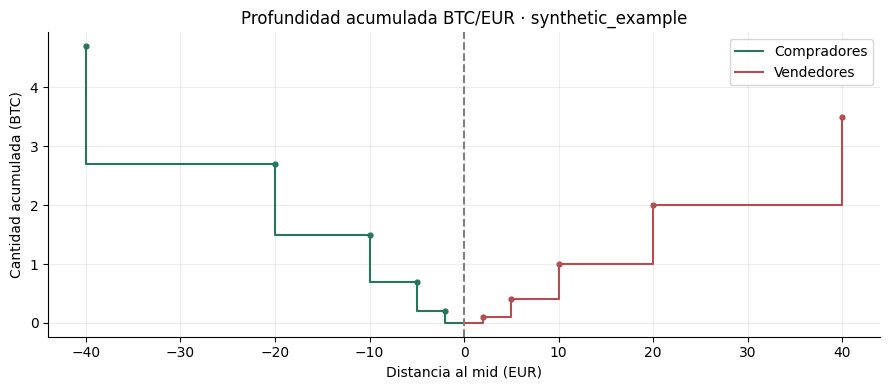

In [5]:
fig, ax = plt.subplots()
mid = features['mid_price']
for df, label, color in [(bids,'Compradores','#267658'),(asks,'Vendedores','#b54c50')]:
    distance = df.price.to_numpy() - mid
    ax.step(np.r_[0,distance], np.r_[0,df.cumulative_btc.to_numpy()], where='post', label=label, color=color)
    ax.scatter(distance, df.cumulative_btc, s=12, color=color)
ax.axvline(0, color='gray', linestyle='--')
ax.set(title=f'Profundidad acumulada BTC/EUR · {source}', xlabel='Distancia al mid (EUR)', ylabel='Cantidad acumulada (BTC)')
ax.legend(); fig.tight_layout(); plt.show()

## 6. Microprice
La aproximación ponderada de primer nivel da mayor peso al ask cuando hay más cantidad en el bid, y viceversa:

$$Microprice=\frac{Ask\cdot Q_{bid}+Bid\cdot Q_{ask}}{Q_{bid}+Q_{ask}}$$

Con el ejemplo inicial: 60.000,6667 EUR. No es un precio ejecutable ni una predicción validada.

In [6]:
print(f"Mid: {features['mid_price']:.4f} EUR")
print(f"Microprice: {features['microprice']:.4f} EUR")

Mid: 60000.0000 EUR
Microprice: 60000.6667 EUR


## 7. Simular una ejecución
Si compras 0,5 BTC en el ejemplo, consumes 0,1 BTC a 60.002 EUR, 0,3 BTC a 60.005 EUR y 0,1 BTC a 60.010 EUR. Precio medio ponderado: 60.005,40 EUR.

Deslizamiento adverso (bps) respecto al mejor precio del lado ejecutado: para compra, `(VWAP / best_ask - 1) * 10000`; para venta, `(1 - VWAP / best_bid) * 10000`. Separaremos este coste del spread y de las comisiones.

El simulador recorre los niveles en orden de ejecución y registra las ejecuciones parciales. No inventa liquidez más allá del snapshot.

In [7]:
result, fills = simulate_market_order(bids, asks, 'buy', .5)
display(fills, pd.Series(result).to_frame('Valor'))

,price,filled_btc,notional_eur
0,60002.0,0.1,6000.2
1,60005.0,0.3,18001.5
2,60010.0,0.1,6001.0


,Valor
side,buy
requested_btc,0.5
filled_btc,0.5
unfilled_btc,0
complete,True
execution_price,60005.4
slippage_bps,0.566648
notional_eur,30002.7


### Tamaño de la orden y deslizamiento
Representamos solo órdenes completamente cubiertas por el snapshot. Para cada tamaño se reinicia el mismo libro: no son operaciones sucesivas. No hay latencia, cancelaciones ni reposición de liquidez modeladas.

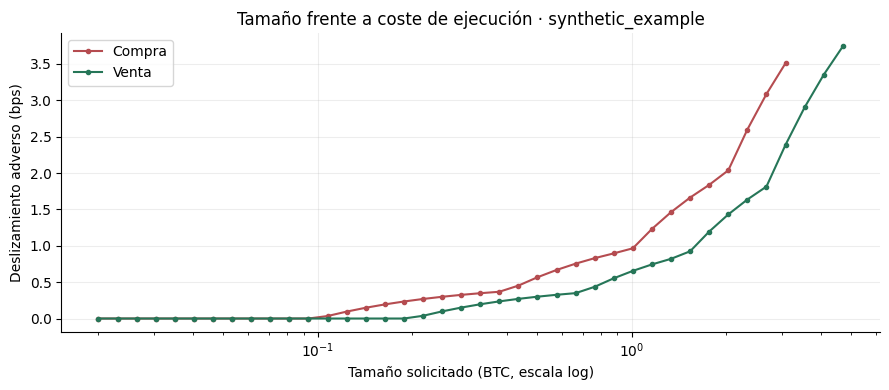

In [8]:
quantities = np.geomspace(min(bids.quantity_btc.iloc[0],asks.quantity_btc.iloc[0])/5,
                         max(bids.quantity_btc.sum(),asks.quantity_btc.sum()),40)
rows=[]
for q in quantities:
    for side in ('buy','sell'):
        r,_ = simulate_market_order(bids,asks,side,q)
        rows.append(r)
scenarios = pd.DataFrame(rows)
fig, ax = plt.subplots()
for side, color, label in [('buy','#b54c50','Compra'),('sell','#267658','Venta')]:
    d = scenarios[(scenarios.side==side)&scenarios.complete]
    ax.plot(d.requested_btc,d.slippage_bps,marker='.',label=label,color=color)
ax.set(xscale='log',xlabel='Tamaño solicitado (BTC, escala log)',ylabel='Deslizamiento adverso (bps)',title=f'Tamaño frente a coste de ejecución · {source}')
ax.legend(); fig.tight_layout(); plt.show()

## 8. Comprobar los cálculos
Estas pruebas utilizan siempre el libro ficticio, incluso en modo real. Validan el caso normal, una orden que agota el libro y la venta al mejor bid.

<div style="background-color:rgba(240,140,0,0.14); border-left:6px solid #f08c00; padding:12px 16px; border-radius:6px;">

<b style="color:#f08c00;">🔎 FASE DE VALIDACIÓN · ¿los cálculos son correctos?</b>

Usamos siempre el **libro de referencia**, cuyos resultados conocemos de antemano, aunque estemos en modo real. Comprobamos tres casos: el normal, una orden que **agota el libro** (`complete=False`) y una venta que cabe en el **mejor bid** (slippage 0). Las mismas pruebas, y otras más, están en `tests/test_orderbook.py`.

</div>

In [9]:
# 🔎 FASE DE VALIDACIÓN: comprobamos las funciones con el libro de referencia
test_bids,test_asks = normalize_book(EXAMPLE)
f=book_features(test_bids,test_asks,5)
assert np.isclose(f['mid_price'],60000)
assert np.isclose(f['bid_depth_btc'],4.7)
assert np.isclose(f['ask_depth_btc'],3.5)
assert np.isclose(f['order_book_imbalance'],1.2/8.2)
assert np.isclose(f['microprice'],60000+2/3)
r,_=simulate_market_order(test_bids,test_asks,'buy',.5)
assert r['complete'] and np.isclose(r['execution_price'],60005.4)
assert np.isclose(r['slippage_bps'],(60005.4/60002-1)*10000)
r,_=simulate_market_order(test_bids,test_asks,'buy',4)
assert not r['complete'] and np.isclose(r['filled_btc'],3.5) and np.isclose(r['unfilled_btc'],.5)
r,_=simulate_market_order(test_bids,test_asks,'sell',.1)
assert r['complete'] and np.isclose(r['execution_price'],59998) and np.isclose(r['slippage_bps'],0)
print('9 comprobaciones superadas (libro de referencia).')

9 comprobaciones superadas (libro de referencia).


<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIÓN · Cálculos verificados</b>

Las 9 comprobaciones pasan. Con el libro de referencia: mid 60.000 €, OBI(5) = 0,1463, microprice 60.000,67 € y compra de 0,5 BTC a un VWAP de 60.005,40 €. Si la orden supera la liquidez del snapshot, el simulador **no inventa** precios: marca `complete=False`.

</div>

## 9. Ejercicios para resolver
**E1.** Calcula el OBI a 1, 3 y 5 niveles. ¿Puede cambiar de signo? Usa el libro de referencia primero y después el real.

**E2.** Simula una compra de 0,05, 0,5 y 2 BTC. Construye una tabla con cantidad, precio medio, coste y slippage. Explica por qué una orden grande puede pagar más por BTC.

**E3.** Repite E2 para ventas. ¿Son simétricos los costes? Si falta profundidad, conserva `complete=False` y no interpretes el precio parcial como precio de toda la orden.

**E4.** Escribe una función que calcule la profundidad en BTC dentro de ±5 bps respecto al mid. Comprueba que ampliar la banda no reduce la profundidad. No uses información más allá del snapshot.

**E5.** Cambia `USE_LIVE_DATA=True`, ejecuta en orden y explica las diferencias con el ejemplo. Registra hora UTC, fuente y número de niveles. Si la API falla, conserva el error y reintenta más tarde; no etiquetes datos ficticios como reales.

In [ ]:
# Libros sobre los que resolvemos los ejercicios: siempre el de referencia y, si estamos en modo real, también el real
ref_bids, ref_asks = normalize_book(EXAMPLE)
BOOKS = {'Referencia': (ref_bids, ref_asks)}
if source != 'synthetic_example':
    BOOKS[f'Kraken ({received_at[:19]} UTC)'] = (bids, asks)
print('Libros:', list(BOOKS))

### E1 · OBI a 1, 3 y 5 niveles

In [ ]:
def obi_table(levels=(1, 3, 5, 10, 20, 50)):
    rows = {}
    for name, (b, a) in BOOKS.items():
        n_max = min(len(b), len(a))
        rows[name] = {f'OBI({n})': book_features(b, a, n)['order_book_imbalance'] for n in levels if n <= n_max}
    return pd.DataFrame(rows).round(4)

display(obi_table())

<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIÓN · E1 · El OBI depende de cuántos niveles mires</b>

| Libro | OBI(1) | OBI(3) | OBI(5) | OBI(10) | OBI(50) |
|---|---|---|---|---|---|
| Referencia | +0,333 | +0,200 | +0,146 | — | — |
| Kraken (19-11-2026 09:28 UTC) | **+0,977** | +0,699 | +0,496 | **−0,059** | −0,218 |
| Kraken (09:32:19 UTC) | **−0,745** | −0,410 | **+0,063** | +0,084 | +0,004 |

- **Sí, puede cambiar de signo.** En el libro real, el primer nivel tenía casi todo el volumen en el lado comprador (+0,98). Con 10 niveles el desequilibrio pasa al lado vendedor (−0,06).
- El OBI **no es una propiedad del mercado, sino de la ventana elegida**. Siempre hay que registrar N junto al valor.
- **Es muy inestable:** cuatro minutos después, el patrón se había invertido (−0,75 en 1 nivel, +0,06 en 5). En otro snapshot tomado **2 s** más tarde, el OBI(1) ya era +0,32.
- Un OBI(1) extremo puede deberse a una sola orden grande en el mejor nivel, y esa orden se puede cancelar en milisegundos.

</div>

### E2 y E3 · Compra y venta de 0,05, 0,5 y 2 BTC

In [ ]:
def slippage_table(b, a, quantities=(0.05, 0.5, 2)):
    rows = []
    for side in ('buy', 'sell'):
        for q in quantities:
            r, _ = simulate_market_order(b, a, side, q)
            rows.append({
                'lado': 'compra' if side == 'buy' else 'venta', 'cantidad_btc': q,
                'mejor_precio': r['best_price'],
                # si no está completa, el VWAP es solo de la parte cubierta: no lo presentamos como precio de toda la orden
                'precio_medio': r['execution_price'] if r['complete'] else np.nan,
                'coste_eur': r['notional_eur'] if r['complete'] else np.nan,
                'slippage_bps': r['slippage_bps'] if r['complete'] else np.nan,
                'slippage_eur': q * abs(r['execution_price'] - r['best_price']) if r['complete'] else np.nan,
                'niveles': r['levels_used'], 'complete': r['complete'],
            })
    return pd.DataFrame(rows)

for name, (b, a) in BOOKS.items():
    print(name)
    display(slippage_table(b, a).round(4))

<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIÓN · E2 · Una orden grande paga más por BTC</b>

| Compra | Referencia: VWAP | slippage | Kraken: VWAP | slippage | niveles |
|---|---|---|---|---|---|
| 0,05 BTC | 60.002,00 € | 0,00 bps | 57.881,18 € | 0,24 bps | 2 |
| 0,5 BTC | 60.005,40 € | 0,57 bps (1,70 €) | 57.882,60 € | 0,48 bps (1,40 €) | 4 |
| 2 BTC | 60.013,85 € | 1,97 bps (23,70 €) | 57.884,02 € | 0,73 bps (8,45 €) | 7 |

Una orden a mercado **consume primero el mejor nivel y después los siguientes, cada vez más caros**. Cuanto mayor es la orden, más niveles recorre y más sube el precio medio. En el libro real, incluso 0,05 BTC ya no cabía en el primer nivel del Ask.

</div>

<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIÓN · E3 · Los costes no son simétricos</b>

| 2 BTC | Referencia | Kraken |
|---|---|---|
| Slippage de compra | 1,97 bps | **0,73 bps** |
| Slippage de venta | 1,41 bps | **0,08 bps** |

En los dos libros **comprar salía más caro que vender**, porque había menos profundidad cerca del mid en el lado ask. En Kraken, vender 2 BTC recorría 3 niveles y comprarlos, 7. La asimetría cambia en cada snapshot.

En las tablas, una orden con `complete=False` aparece sin precio medio. El VWAP de la parte cubierta **no es** el precio de toda la orden.

</div>

### E4 · Profundidad dentro de ±5 bps del mid

In [ ]:
print(inspect.getsource(depth_within_bps))

In [ ]:
BANDS = [0, 1, 2, 5, 10, 25]
for name, (b, a) in BOOKS.items():
    table = pd.DataFrame([depth_within_bps(b, a, band) for band in BANDS]).set_index('band_bps')
    print(name)
    display(table[['bid_depth_btc', 'ask_depth_btc', 'bid_levels', 'ask_levels', 'complete_bid', 'complete_ask']].round(4))
    # 🔎 Ampliar la banda nunca puede reducir la profundidad
    assert table.bid_depth_btc.is_monotonic_increasing and table.ask_depth_btc.is_monotonic_increasing
print('Profundidad no decreciente al ampliar la banda: OK')

<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIÓN · E4 · Profundidad por banda de precio</b>

| Banda | Referencia bid / ask | Kraken bid / ask |
|---|---|---|
| ±1 bps | 0,7 / 0,4 BTC | 3,18 / 3,16 BTC |
| ±5 bps | 2,7 / 2,0 BTC | 6,67 / 6,63 BTC |
| ±10 bps | 4,7 / 3,5 BTC ⚠️ | 24,2 / 21,0 BTC |
| ±25 bps | 4,7 / 3,5 BTC ⚠️ | 101,9 / 43,5 BTC |

- **Medir en bps del mid permite comparar** libros de precios distintos. Contar niveles no lo permite, porque cada nivel puede estar a una distancia diferente.
- ⚠️ Cuando la banda llega al último nivel recibido (`complete=False`), la cifra es solo un **mínimo**: puede haber más liquidez fuera del snapshot. En la referencia ocurre a partir de ±10 bps.
- En Kraken, a ±25 bps, había más del doble de BTC en el lado comprador que en el vendedor. El desequilibrio también depende de la banda, igual que el OBI depende de N.

</div>

### E5 · Libro real frente al de referencia
Cambia `LIVE_E5` a `True` para descargar un snapshot real y compararlo con la referencia. Cada consulta se registra (hora UTC, fuente, niveles y métricas) en `data/raw/p02_snapshots.csv`, que Git no sube. Si la API falla, se muestra el error y no se sustituye por datos ficticios.

In [ ]:
LIVE_E5 = False
QTY_E5 = 0.5

def snapshot_record(name, b, a, received, src):
    f = book_features(b, a, 5)
    d5 = depth_within_bps(b, a, 5)
    buy, _ = simulate_market_order(b, a, 'buy', QTY_E5)
    sell, _ = simulate_market_order(b, a, 'sell', QTY_E5)
    return {'libro': name, 'received_at_utc': received, 'source': src, 'levels': min(len(b), len(a)),
            'mid_price': f['mid_price'], 'spread_eur': f['best_ask'] - f['best_bid'], 'spread_bps': f['spread_bps'],
            'obi_1': book_features(b, a, 1)['order_book_imbalance'], 'obi_5': f['order_book_imbalance'],
            'microprice_minus_mid': f['microprice'] - f['mid_price'],
            'depth_5bps_bid_btc': d5['bid_depth_btc'], 'depth_5bps_ask_btc': d5['ask_depth_btc'],
            f'slip_buy_{QTY_E5}_bps': buy['slippage_bps'] if buy['complete'] else np.nan,
            f'slip_sell_{QTY_E5}_bps': sell['slippage_bps'] if sell['complete'] else np.nan}

records = [snapshot_record('Referencia', ref_bids, ref_asks, None, 'synthetic_example')]
if LIVE_E5:
    try:
        live_raw, live_received = fetch_kraken_book(PAIR, LEVELS)
        live_bids, live_asks = normalize_book(live_raw)
    except Exception as exc:
        print(f'⛔ La consulta falló: {type(exc).__name__}: {exc}. Reintenta más tarde.')
    else:
        rec = snapshot_record('Kraken', live_bids, live_asks, live_received, 'kraken_public_depth')
        records.append(rec)
        root = next((d for d in [Path.cwd(), *Path.cwd().parents] if (d / 'pyproject.toml').exists()), Path.cwd())
        log = root / 'data' / 'raw' / 'p02_snapshots.csv'
        log.parent.mkdir(parents=True, exist_ok=True)
        pd.DataFrame([rec]).to_csv(log, mode='a', header=not log.exists(), index=False)
        print('Registrado en', log)
else:
    print('Consulta en vivo desactivada (LIVE_E5 = False).')
display(pd.DataFrame(records).set_index('libro').T)

<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIÓN · E5 · Kraken (19-11-2026 09:28 UTC, 50 niveles por lado) frente a la referencia</b>

| Métrica | Referencia | Kraken |
|---|---|---|
| Mid | 60.000 € | 57.879,75 € |
| Spread | 4,0 € (0,667 bps) | **0,1 € (0,017 bps)** |
| OBI(1) / OBI(5) | +0,333 / +0,146 | +0,977 / +0,496 |
| Microprice − Mid | +0,67 € | +0,05 € |
| Profundidad ±5 bps (bid / ask) | 2,7 / 2,0 BTC | 6,67 / 6,63 BTC |
| Slippage compra / venta de 0,5 BTC | 0,57 / 0,30 bps | 0,48 / 0,03 bps |

- El libro real es **mucho más estrecho** (spread de 1 tick) y **más profundo** cerca del mid que el de referencia.
- Aun así, el **mejor nivel tenía muy poco volumen**: comprar 0,05 BTC ya recorría 2 niveles. Un spread pequeño no garantiza una ejecución barata.
- El microprice queda casi en el mid (+0,05 €) porque, con un spread de 0,1 €, el precio apenas puede separarse del mid.
- Es **un único snapshot**: todo esto cambia en segundos. Para comparar de verdad hace falta registrar muchas consultas.

</div>

## 10. Interpretación y conclusiones

<div style="background-color:rgba(47,158,68,0.14); border-left:6px solid #2f9e44; padding:12px 16px; border-radius:6px;">

<b style="color:#2f9e44;">✅ CONCLUSIONES DE LA PRÁCTICA P02</b>

1. **El mejor precio solo vale para el volumen del mejor nivel.** En la referencia, el mejor ask es 60.002 €, pero comprar 0,5 BTC cuesta de media 60.005,40 €.
2. **El slippage crece con el tamaño y no es simétrico.** Depende de la profundidad de cada lado, que cambia en cada snapshot.
3. **El OBI depende de la ventana:** en el libro real pasó de +0,98 (1 nivel) a −0,06 (10 niveles). Sin indicar N, el valor no significa nada.
4. **Microprice ≠ precio ejecutable.** Es una referencia ponderada, no una predicción validada.
5. **El snapshot es parcial:** fuera de los niveles pedidos puede haber más liquidez, y las bandas que llegan al borde son solo un mínimo.

**¿Qué limitaciones tiene este método para un backtest?**
- Un snapshot es una foto. No modela latencia, cancelaciones ni la reposición de liquidez después de nuestra orden. Además, nuestra orden cambiaría el libro (impacto).
- El libro visible de nivel 2 no incluye órdenes ocultas ni icebergs, ni la cola de prioridad dentro de cada nivel.
- La hora de recepción local no es la hora del evento en el exchange, y en un histórico podría colarse información del futuro (*look-ahead*).

**¿Qué datos harían falta para evaluar si el OBI anticipa retornos?**
- Una **serie de snapshots o eventos del libro**, alineados en el tiempo y guardados con la misma N o banda.
- Los **trades ejecutados** (P03) y los retornos futuros, medidos en horizontes fijos (por ejemplo, 1 s, 10 s y 60 s).
- Separar los datos en entrenamiento y prueba en el orden temporal, compararlos con un modelo de referencia sin OBI y descontar los costes: spread, slippage y comisiones (0,80 % taker en el nivel 1 de Kraken).

📄 Resumen en `docs/conclusiones/P02_order_book.md`

</div>

**Siguiente práctica P03:** operaciones ejecutadas, volumen, VWAP y desequilibrio de trades. El OFI basado en cambios del libro se evaluará con eventos o snapshots sucesivos, no con un único snapshot.